# 08 · Structured Output, Routing & Parallelism  🟠 Advanced

Four production workflow patterns:
1. **Structured output**: get typed Pydantic objects instead of free text
2. **Routing**: an LLM classifier picks the branch
3. **Parallel fan-out / fan-in**: independent nodes run at the same time
4. **Map-reduce with `Send`**: a dynamic number of parallel workers
5. **Evaluator-optimizer**: generate → grade → improve loop

In [1]:
from helpers import get_llm, show_graph, print_messages

llm = get_llm()   # ChatAnthropic -> Claude, key read from CLAUDE_KEY in .env

## 1. Structured output

`with_structured_output(Model, method="json_schema")` makes Claude return JSON that matches your schema
(Claude's native *structured outputs* feature) and parses it into the Pydantic model.

> ℹ️ Always pass `method="json_schema"` with Claude Opus 5.5. The default method relies on *forced* tool calls, which this model doesn't support.

In [2]:
from typing import Literal
from pydantic import BaseModel, Field

class ReviewAnalysis(BaseModel):
    sentiment: Literal["positive", "negative", "mixed"]
    rating: int = Field(description="Estimated star rating from 1 to 5")
    pros: list[str]
    cons: list[str]

analyzer = llm.with_structured_output(ReviewAnalysis, method="json_schema")
review = "Battery lasts two days and the screen is gorgeous, but it overheats while gaming and the charger is slow."
result = analyzer.invoke(f"Analyze this product review:\n{review}")
print(type(result).__name__)
result

ReviewAnalysis


ReviewAnalysis(sentiment='mixed', rating=3, pros=['Battery lasts two days', 'Gorgeous screen'], cons=['Overheats while gaming', 'Slow charger'])

## 2. Routing with an LLM classifier

A cheap, fast classifier (`effort="low"`) decides which specialist handles the request.

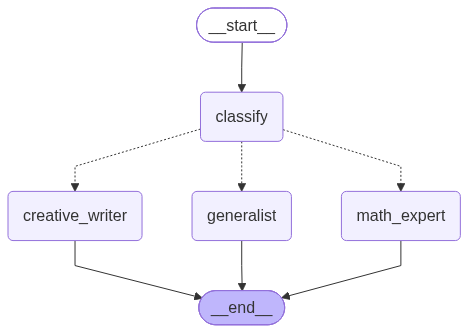

In [3]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from helpers import get_llm

class Route(BaseModel):
    destination: Literal["math", "creative", "general"] = Field(
        description="math: calculations/numbers; creative: poems, stories, jokes; general: everything else")

router_llm = get_llm(effort="low").with_structured_output(Route, method="json_schema")

class RouterState(TypedDict):
    question: str
    destination: str
    answer: str

def classify(state: RouterState):
    return {"destination": router_llm.invoke(state["question"]).destination}

def math_expert(state: RouterState):
    return {"answer": llm.invoke(f"Solve step by step, briefly:\n{state['question']}").text}

def creative_writer(state: RouterState):
    return {"answer": llm.invoke(f"Be playful and creative, max 6 lines:\n{state['question']}").text}

def generalist(state: RouterState):
    return {"answer": llm.invoke(f"Answer in 2 sentences:\n{state['question']}").text}

def route(state: RouterState) -> Literal["math_expert", "creative_writer", "generalist"]:
    return {"math": "math_expert", "creative": "creative_writer"}.get(state["destination"], "generalist")

b = StateGraph(RouterState)
for fn in (classify, math_expert, creative_writer, generalist):
    b.add_node(fn)
b.add_edge(START, "classify")
b.add_conditional_edges("classify", route)
for n in ("math_expert", "creative_writer", "generalist"):
    b.add_edge(n, END)
router_graph = b.compile()
show_graph(router_graph)

In [4]:
for q in ["What is 15% of 2,480?", "Write a haiku about monsoon rain", "Why is the sky blue?"]:
    out = router_graph.invoke({"question": q})
    print(f"❓ {q}\n➡️  routed to: {out['destination']}\n{out['answer']}\n")

❓ What is 15% of 2,480?
➡️  routed to: math
**Step 1:** Find 10% of 2,480: 2,480 ÷ 10 = **248**

**Step 2:** Find 5% (half of 10%): 248 ÷ 2 = **124**

**Step 3:** Add them for 15%: 248 + 124 = **372**

**Answer: 372**



❓ Write a haiku about monsoon rain
➡️  routed to: creative
**Monsoon Mischief**

Sky spills its whole cup,
frogs host karaoke night,
my umbrella quits. ☔🐸



❓ Why is the sky blue?
➡️  routed to: general
The sky looks blue because sunlight is scattered by gas molecules in the atmosphere, and shorter wavelengths like blue are scattered much more strongly than longer ones like red, a process called Rayleigh scattering. Violet light scatters even more, but the sky appears blue rather than violet because sunlight contains less violet, some of it is absorbed high in the atmosphere, and our eyes are more sensitive to blue.



## 3. Parallel fan-out / fan-in

Edges from `START` to three nodes → they run **in the same step, concurrently**.
`add_edge([a, b, c], "aggregate")` waits for **all** of them.

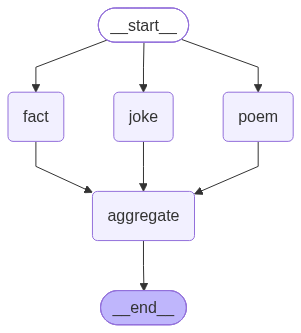

😂 I'd tell you a coffee joke, but it might be a little too *grounds*-breaking.

📝 Dark ritual poured before the light breaks through,
I wake for you, though you're the one who wakes me too.

💡 Coffee "beans" aren't actually beans; they're the seeds of a bright red, cherry-like fruit that grows on coffee shrubs.

⏱️ 3.4s for 3 LLM calls (in parallel)


In [5]:
import time

class ParallelState(TypedDict):
    topic: str
    joke: str
    poem: str
    fact: str
    combined: str

def joke(state):  return {"joke": llm.invoke(f"One-line joke about {state['topic']}.").text}
def poem(state):  return {"poem": llm.invoke(f"Two-line poem about {state['topic']}.").text}
def fact(state):  return {"fact": llm.invoke(f"One surprising fact about {state['topic']}, one sentence.").text}

def aggregate(state):
    return {"combined": f"😂 {state['joke']}\n\n📝 {state['poem']}\n\n💡 {state['fact']}"}

b = StateGraph(ParallelState)
for fn in (joke, poem, fact, aggregate):
    b.add_node(fn)
for n in ("joke", "poem", "fact"):
    b.add_edge(START, n)
b.add_edge(["joke", "poem", "fact"], "aggregate")
b.add_edge("aggregate", END)
parallel_graph = b.compile()
show_graph(parallel_graph)

t0 = time.time()
print(parallel_graph.invoke({"topic": "coffee"})["combined"])
print(f"\n⏱️ {time.time() - t0:.1f}s for 3 LLM calls (in parallel)")

## 4. Map-reduce with `Send`

When the **number** of parallel tasks is only known at runtime (e.g. one worker per section),
a conditional edge can return a list of `Send(node, private_input)` objects.
Each worker's output is merged with a reducer (`operator.add`).

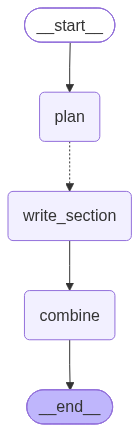

In [6]:
import operator
from typing import Annotated
from langgraph.types import Send

class Outline(BaseModel):
    sections: list[str] = Field(description="3 short section titles")

planner = llm.with_structured_output(Outline, method="json_schema")

class ReportState(TypedDict):
    topic: str
    sections: list[str]
    drafts: Annotated[list[str], operator.add]     # each worker appends here
    report: str

class SectionInput(TypedDict):                     # what each worker receives
    topic: str
    section: str

def plan(state: ReportState):
    sections = planner.invoke(f"Plan a 3-section mini report on: {state['topic']}").sections
    print("📋 plan:", sections)
    return {"sections": sections}

def assign_workers(state: ReportState):
    return [Send("write_section", {"topic": state["topic"], "section": s}) for s in state["sections"]]

def write_section(state: SectionInput):
    text = llm.invoke(f"Write 2 sentences for the section '{state['section']}' of a report on {state['topic']}.").text
    return {"drafts": [f"### {state['section']}\n{text}"]}

def combine(state: ReportState):
    return {"report": f"# {state['topic']}\n\n" + "\n\n".join(state["drafts"])}

b = StateGraph(ReportState)
b.add_node(plan); b.add_node(write_section); b.add_node(combine)
b.add_edge(START, "plan")
b.add_conditional_edges("plan", assign_workers, ["write_section"])
b.add_edge("write_section", "combine")
b.add_edge("combine", END)
report_graph = b.compile()
show_graph(report_graph)

In [7]:
from IPython.display import Markdown
out = report_graph.invoke({"topic": "Electric vehicles in India"})
Markdown(out["report"])

📋 plan: ['Current EV Market Landscape in India', 'Government Policies and Infrastructure Development', 'Challenges and Future Outlook']


# Electric vehicles in India

### Current EV Market Landscape in India
India's electric vehicle market has grown rapidly in recent years, with annual EV sales nearing two million units in FY2024–25, though EVs still make up only a modest share of total vehicle sales. Two-wheelers and three-wheelers dominate the market, supported by government initiatives such as the FAME and PM E-DRIVE schemes, production-linked incentives for batteries and vehicles, and an expanding but still limited charging infrastructure.

### Government Policies and Infrastructure Development
The Government of India has accelerated electric vehicle adoption through initiatives such as the FAME II scheme and its successor, PM E-DRIVE, along with Production-Linked Incentive (PLI) schemes for advanced battery manufacturing and a reduced GST rate of 5% on EVs. These measures are complemented by efforts to expand public charging infrastructure, including Ministry of Power guidelines and state-level EV policies that encourage private investment in charging stations along highways and in urban centres.

### Challenges and Future Outlook
Despite strong policy support through initiatives like FAME and the PLI scheme, India's electric vehicle sector still faces significant hurdles, including inadequate charging infrastructure, high upfront costs, heavy reliance on imported battery cells, and consumer concerns over range and resale value. Looking ahead, expanding domestic battery manufacturing, falling technology costs, and growing adoption in the two- and three-wheeler segments position India to make substantial progress toward its goal of 30% EV penetration in new vehicle sales by 2030.

## 5. Evaluator-optimizer loop

One LLM generates, another grades with a structured verdict; failures loop back **with feedback**.

In [8]:
class Verdict(BaseModel):
    grade: Literal["pass", "fail"]
    feedback: str = Field(description="What to fix if failing")

evaluator = llm.with_structured_output(Verdict, method="json_schema")

class TweetState(TypedDict):
    topic: str
    tweet: str
    feedback: str
    rounds: int

def write_tweet(state: TweetState):
    prompt = f"Write a tweet about {state['topic']}."
    if state.get("feedback"):
        prompt += f"\nPrevious attempt:\n{state['tweet']}\nFix this feedback: {state['feedback']}"
    tweet = llm.invoke(prompt + "\nOutput only the tweet.").text
    return {"tweet": tweet, "rounds": state.get("rounds", 0) + 1}

def grade(state: TweetState):
    v = evaluator.invoke(
        "Grade this tweet strictly. PASS only if ALL hold: under 200 characters, contains exactly one hashtag, "
        f"contains a number, ends with a question.\n\nTweet:\n{state['tweet']}")
    print(f"round {state['rounds']}: {v.grade.upper()} - {v.feedback[:100]}")
    return {"feedback": "" if v.grade == "pass" else v.feedback}

def done(state: TweetState) -> Literal["write_tweet", "__end__"]:
    return END if not state["feedback"] or state["rounds"] >= 3 else "write_tweet"

b = StateGraph(TweetState)
b.add_node(write_tweet); b.add_node(grade)
b.add_edge(START, "write_tweet"); b.add_edge("write_tweet", "grade")
b.add_conditional_edges("grade", done)
opt_graph = b.compile()
print("\nFinal tweet:\n", opt_graph.invoke({"topic": "learning LangGraph"})["tweet"])

round 1: FAIL - Fails all four criteria. (1) Length: about 330 characters, well over the 200-character limit, so cut


round 2: PASS - All criteria are met. The tweet is about 170 characters, under the 200 limit. It has exactly one has

Final tweet:
 Spent 2 days on #LangGraph and it clicked: nodes are steps, edges are logic, state is memory. Agents finally feel like engineering, not magic. What made it click for you?


## ✅ Recap
| Pattern | Key API |
|---|---|
| Typed LLM output | `with_structured_output(Model, method="json_schema")` |
| LLM routing | classifier node + `add_conditional_edges` |
| Static parallelism | multiple edges from one node; `add_edge([...], join)` |
| Dynamic parallelism | conditional edge returning `[Send(...), ...]` + reducer |
| Self-correction | evaluator with structured verdict + loop |